# El cocodrilo que revela el Egipto anterior al desierto

## Una EDA para reconstruir el mundo escondido bajo la Gran Esfinge

En 1927, un cráneo procedente de la formación Mokattam, cerca de El Cairo, fue clasificado como *Tomistoma cairense*. Casi un siglo después, una tomografía y una nueva comparación anatómica han demostrado que pertenece a un linaje distinto: ***Herugavialis cairensis***.

El fósil y la Gran Esfinge comparten roca, no época. Esa diferencia abre una pregunta más interesante que el titular original:

> **¿Qué nos cuentan los registros de gaviales sobre el Egipto tropical y sobre el antiguo océano que conectaba varios continentes?**

El objetivo no es predecir ni reconstruir un clima exacto. Es explorar el registro fósil, separar diversidad de esfuerzo de muestreo y comprobar si la imagen de un Mediterráneo lleno de gaviales está respaldada por los datos disponibles.

## La ruta de la investigación

Seguiré cinco pistas:

1. **Dos escalas de tiempo:** cuánto separa al fósil de la Esfinge.
2. **Egipto no tenía un solo gavial:** qué especies aparecen y en qué ambientes.
3. **El mar como autopista:** cómo cambia el peso de los registros costeros y continentales.
4. **Un mapa sin mapa:** qué paleolatitudes ocuparon estos animales durante 120 millones de años.
5. **La trampa del registro fósil:** hasta qué punto una aparente explosión de diversidad coincide con más yacimientos estudiados.

## Cuatro ideas antes de mirar los datos

**Un gavial no es exactamente un cocodrilo.** Todos son crocodilianos, pero los gaviales forman una rama caracterizada por hocicos largos y estrechos, muy adecuados para capturar peces.

**La formación Mokattam es mucho más antigua que la Esfinge.** Sus calizas se formaron durante el Eoceno, cuando el norte de Egipto estaba cubierto por aguas tropicales poco profundas. Los constructores egipcios tallaron después el monumento en esa roca.

**Un registro no equivale a un animal.** La Paleobiology Database reúne menciones publicadas. Varias pueden proceder de un mismo yacimiento o corresponder a la misma especie.

**Ausencia de fósiles no significa ausencia de animales.** La fosilización, la exposición de las rocas y el interés científico varían enormemente entre lugares y épocas.

## De dónde salen los datos

La fuente principal es una descarga reproducible de **Paleobiology Database (PBDB)** para la superfamilia Gavialoidea, recuperada el 14 de octubre de 2026. Incluye coordenadas actuales y paleogeográficas, edades, formación geológica, ambiente sedimentario y taxonomía aceptada en la base. La consulta exacta se conserva en la documentación del proyecto y parte de `https://paleobiodb.org/data1.2/occs/list.csv?base_name=Gavialoidea`.

La interpretación de *Herugavialis cairensis* procede del estudio de Burke y colaboradores publicado en *Royal Society Open Science*. El artículo aporta la revisión anatómica, la tomografía y una filogenia calibrada en el tiempo.

Hay una discrepancia útil: la descarga de PBDB todavía conserva el nombre antiguo, *Tomistoma cairense*. Mantendré el valor original y crearé una columna actualizada. Así el notebook documenta el cambio en lugar de ocultarlo.

**Unidad principal:** una colección paleontológica con una especie identificada. Para evitar pseudorreplicación, las comparaciones ambientales eliminan duplicados de especie dentro de una misma colección.

In [1]:
# importo las herramientas necesarias para cargar, resumir y visualizar
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# localizo la raíz del proyecto tanto desde la carpeta principal como desde notebooks
ruta_proyecto = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ruta_raw = ruta_proyecto / "data" / "raw"
ruta_processed = ruta_proyecto / "data" / "processed"
ruta_imagenes = ruta_proyecto / "img"

ruta_processed.mkdir(parents=True, exist_ok=True)
ruta_imagenes.mkdir(parents=True, exist_ok=True)

# mantengo una estética común con los EDA de Nebula
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.figsize": (12, 6.5),
    "font.size": 12,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110,
})

color_nebula = "#7257D5"
color_arena = "#D9A441"
color_mar = "#2A9D8F"
color_tierra = "#C66A3D"
color_tinta = "#24223A"
color_gris = "#B8BBC4"

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")

## 1. Carga y primera inspección

La consulta de PBDB solicitó todas las ocurrencias atribuidas a Gavialoidea y añadió información geográfica, estratigráfica, ambiental y taxonómica. Trabajo con la copia local para que el resultado no cambie si la base se actualiza mañana.

In [2]:
# cargo la instantánea original sin modificarla
archivo_pbdb = ruta_raw / "pbdb_gavialoidea.csv"
df_raw = pd.read_csv(archivo_pbdb)

print(f"Registros descargados: {len(df_raw):,}")
print(f"Columnas disponibles: {df_raw.shape[1]}")
display(
    df_raw[[
        "accepted_name", "accepted_rank", "max_ma", "min_ma",
        "cc", "formation", "environment"
    ]].head()
)

Registros descargados: 386
Columnas disponibles: 68


,accepted_name,accepted_rank,max_ma,min_ma,cc,formation,environment
0,Gavialoidea,superfamily,59.24,56.00,US,Vincentown,NaN
1,Gavialoidea,superfamily,59.24,56.00,US,Vincentown,NaN
2,Thoracosaurus neocesariensis,species,59.24,56.00,US,Vincentown,NaN
3,Gavialis,genus,0.13,0.00,IN,Babladanga,fluvial indet.
4,Tomistoma,genus,3.60,2.58,TD,NaN,fluvial-lacustrine indet.


### Comprobaciones antes de analizar

Necesito distinguir tres niveles:

- **ocurrencia:** una identificación publicada;
- **colección:** un yacimiento o conjunto de procedencia;
- **taxón:** el nombre aceptado en PBDB.

También compruebo edades imposibles, duplicados exactos y disponibilidad de paleocoordenadas. Los nombres por encima de especie se conservarán para auditoría, pero no entrarán en el cálculo de diversidad específica.

In [3]:
# resumo la cobertura y los principales controles de calidad
comprobaciones = pd.Series({
    "Filas duplicadas exactas": int(df_raw.duplicated().sum()),
    "Colecciones únicas": int(df_raw["collection_no"].nunique()),
    "Registros identificados a especie": int(df_raw["accepted_rank"].eq("species").sum()),
    "Especies aceptadas": int(
        df_raw.loc[df_raw["accepted_rank"].eq("species"), "accepted_name"].nunique()
    ),
    "Registros con paleocoordenadas": int(
        df_raw[["paleolat", "paleolng"]].notna().all(axis=1).sum()
    ),
    "Edades con límites invertidos": int((df_raw["max_ma"] < df_raw["min_ma"]).sum()),
}, name="valor")

display(comprobaciones.to_frame())

,valor
Filas duplicadas exactas,0
Colecciones únicas,338
Registros identificados a especie,229
Especies aceptadas,67
Registros con paleocoordenadas,365
Edades con límites invertidos,0


La instantánea contiene **386 ocurrencias en 338 colecciones**. Solo 229 registros están identificados a nivel de especie; representan 67 nombres aceptados. Esta diferencia es importante: contar todas las filas como “especies” multiplicaría artificialmente la diversidad.

## 2. Limpieza y actualización del protagonista

Calculo una edad central como punto medio entre la edad máxima y mínima asignada a cada registro. Es una simplificación descriptiva, no la fecha exacta del fósil.

Para mantener coherencia con la filogenia del nuevo estudio, reemplazo únicamente el nombre antiguo del protagonista. No intento revisar toda la taxonomía histórica de PBDB.

In [4]:
# creo una copia de trabajo y convierto las columnas esenciales
df = df_raw.copy()
for columna in ["max_ma", "min_ma", "paleolat", "paleolng"]:
    df[columna] = pd.to_numeric(df[columna], errors="coerce")

df["edad_central_ma"] = (df["max_ma"] + df["min_ma"]) / 2
df["taxon_original"] = df["accepted_name"]
df["taxon_actualizado"] = df["accepted_name"].replace({
    "Tomistoma cairense": "Herugavialis cairensis"
})

# clasifico el ambiente con reglas explícitas y conservadoras
ambiente = df["environment"].fillna("").str.lower()
palabras_mar = "marine|coastal|estuary|shoreface|lagoon|paralic|foreshore|carbonate"
palabras_tierra = "fluvial|lacustr|channel|floodplain|terrestrial|pond|river|swamp"

df["ambiente_agrupado"] = np.select(
    [
        ambiente.str.contains(palabras_mar, regex=True),
        ambiente.str.contains(palabras_tierra, regex=True),
    ],
    ["Costero o marino", "Continental"],
    default="Sin clasificar",
)

# conservo solo especies del Cretácico inferior en adelante para las comparaciones
df_especies = df.loc[
    df["accepted_rank"].eq("species")
    & df["edad_central_ma"].between(0, 120, inclusive="both")
].copy()

# una especie cuenta una sola vez por colección
df_colecciones = (
    df_especies.sort_values("occurrence_no")
    .drop_duplicates(["collection_no", "taxon_actualizado"])
    .copy()
)

print(f"Ocurrencias de especie analizadas: {len(df_especies):,}")
print(f"Pares únicos colección-especie: {len(df_colecciones):,}")
print(
    "Nombre actualizado:",
    df.loc[df["taxon_original"].eq("Tomistoma cairense"), "taxon_actualizado"].iloc[0],
)

Ocurrencias de especie analizadas: 228
Pares únicos colección-especie: 223
Nombre actualizado: Herugavialis cairensis


In [5]:
# guardo una versión trazable con las variables derivadas
columnas_salida = [
    "occurrence_no", "collection_no", "taxon_original", "taxon_actualizado",
    "accepted_rank", "max_ma", "min_ma", "edad_central_ma", "cc",
    "lat", "lng", "paleolat", "paleolng", "formation", "environment",
    "ambiente_agrupado", "reference_no"
]
df[columnas_salida].to_csv(
    ruta_processed / "registros_gavialoidea_limpios.csv",
    index=False,
    encoding="utf-8-sig",
)

## 3. La Esfinge y el fósil comparten piedra, no tiempo

El titular puede inducir a imaginar un animal relacionado con el Egipto faraónico. La escala temporal demuestra lo contrario: el gavial vivió alrededor de **45 millones de años** antes del presente, mientras que la Esfinge tiene aproximadamente **4.500 años**.

Para que ambos valores puedan verse en la misma gráfica utilizaré una escala logarítmica. También añado los 99 años transcurridos entre la descripción científica de 1927 y la revisión de 2026.

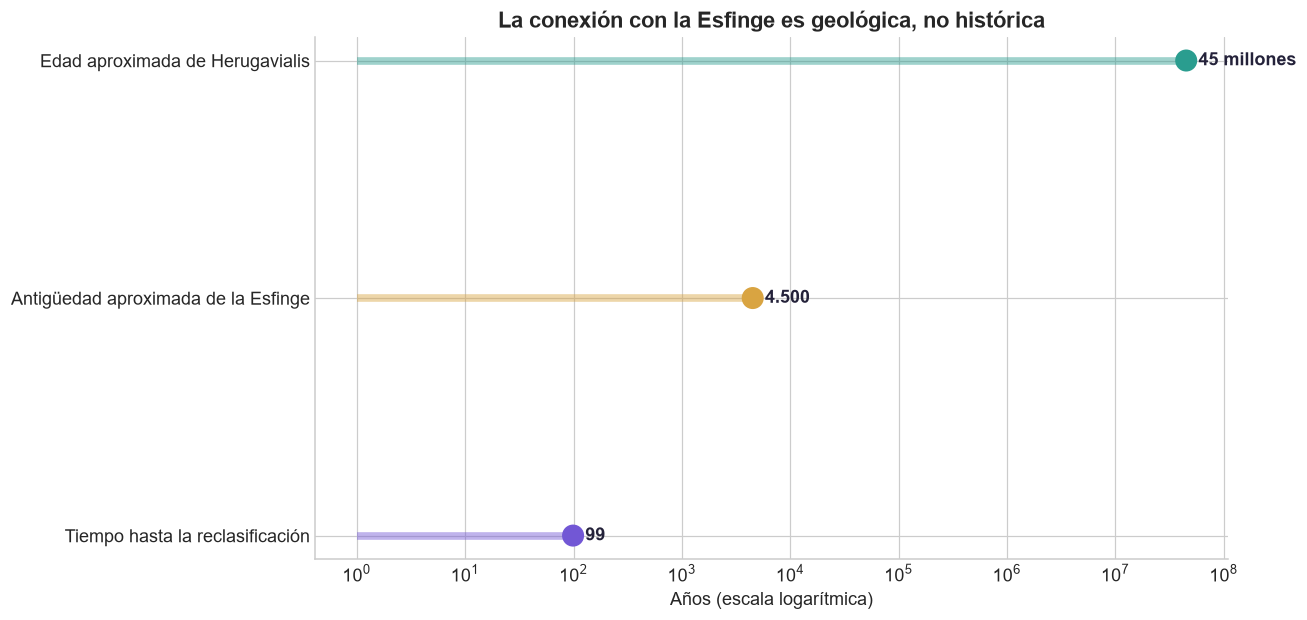

El fósil es aproximadamente 10,000 veces más antiguo que la Esfinge.


In [6]:
# comparo órdenes de magnitud, no fechas arqueológicas exactas
escalas = pd.DataFrame({
    "evento": [
        "Edad aproximada de Herugavialis",
        "Antigüedad aproximada de la Esfinge",
        "Tiempo hasta la reclasificación",
    ],
    "años": [45_000_000, 4_500, 99],
    "etiqueta": ["45 millones", "4.500", "99"],
})

fig, ax = plt.subplots(figsize=(12, 5.8))
colores = [color_mar, color_arena, color_nebula]
y = np.arange(len(escalas))

ax.hlines(y, 1, escalas["años"], color=colores, linewidth=5, alpha=0.45)
ax.scatter(escalas["años"], y, s=180, color=colores, zorder=3)
ax.set_xscale("log")
ax.set_yticks(y, escalas["evento"])
ax.invert_yaxis()
ax.set_xlabel("Años (escala logarítmica)")
ax.set_title("La conexión con la Esfinge es geológica, no histórica")

for pos, fila in escalas.iterrows():
    ax.annotate(
        fila["etiqueta"],
        (fila["años"], pos),
        xytext=(8, 0),
        textcoords="offset points",
        va="center",
        fontweight="bold",
        color=color_tinta,
    )

fig.tight_layout()
fig.savefig(ruta_imagenes / "01_dos_escalas_tiempo.png", dpi=180, bbox_inches="tight")
plt.show()

razon_edades = escalas.loc[0, "años"] / escalas.loc[1, "años"]
print(f"El fósil es aproximadamente {razon_edades:,.0f} veces más antiguo que la Esfinge.")

### Primera pista

El fósil es aproximadamente **10.000 veces más antiguo** que el monumento. La sorpresa no es que un cocodrilo conviviera con los faraones, sino que la piedra de uno de los monumentos más famosos del mundo conserva el recuerdo de un mar tropical remotísimo.

## 4. Egipto no albergó un único gavial

Selecciono los registros de Egipto y uno las apariciones del mismo nombre. La barra representa todo el intervalo temporal asignado por PBDB: cuanto más larga, mayor es la incertidumbre o la duración combinada de los registros.

La base todavía contiene otros nombres históricos susceptibles de revisión. Por eso esta figura describe el estado de la base y no pretende resolver la taxonomía egipcia completa.

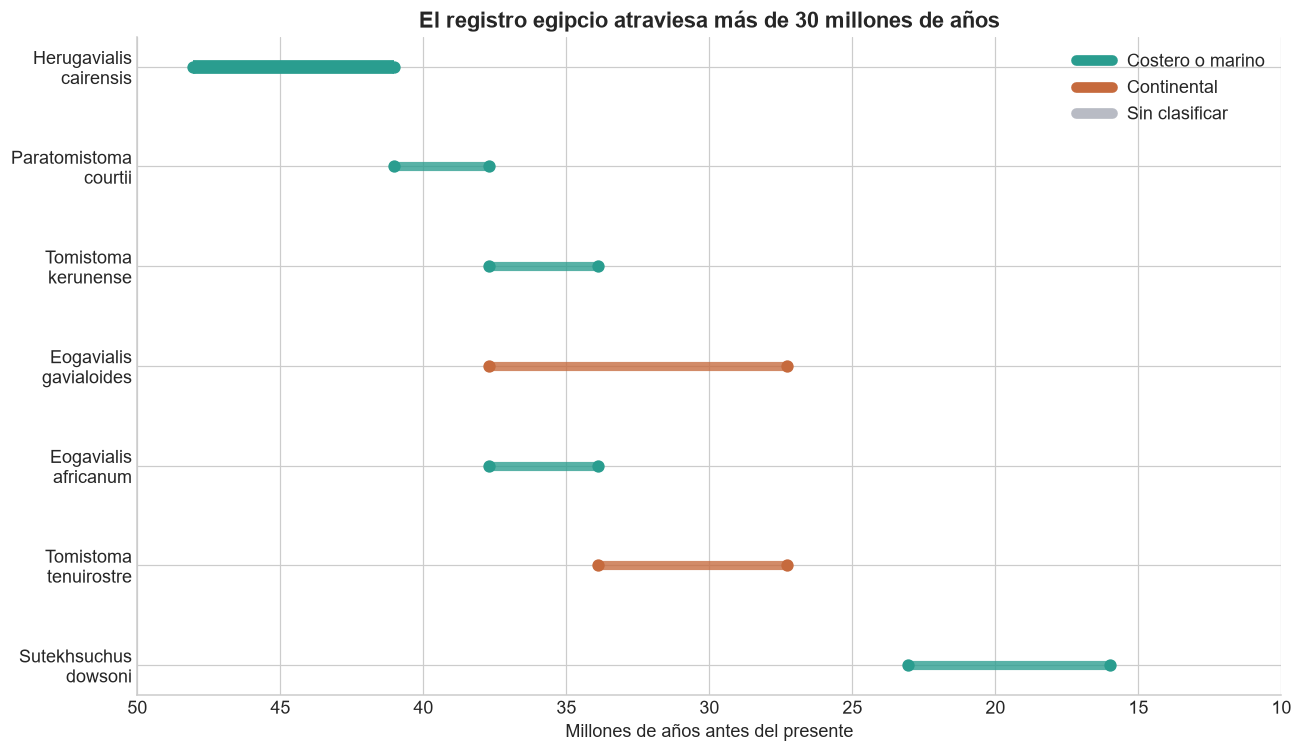

,taxon_actualizado,edad_maxima_ma,edad_minima_ma,colecciones,ambiente,formaciones
4,Sutekhsuchus dowsoni,23.04,15.98,3,Costero o marino,Moghara
6,Tomistoma tenuirostre,33.90,27.30,1,Continental,Jebel Qatrani
0,Eogavialis africanum,37.71,33.90,1,Costero o marino,Qasr el-Sagha
1,Eogavialis gavialoides,37.71,27.30,1,Continental,Jebel Qatrani
5,Tomistoma kerunense,37.71,33.90,1,Costero o marino,Birket Qarun
3,Paratomistoma courtii,41.03,37.71,1,Costero o marino,Gehannam
2,Herugavialis cairensis,48.07,41.03,1,Costero o marino,Mokattam


In [7]:
# resumo los intervalos de las especies registradas en Egipto
egipto = (
    df_especies.loc[df_especies["cc"].eq("EG")]
    .groupby("taxon_actualizado", as_index=False)
    .agg(
        edad_maxima_ma=("max_ma", "max"),
        edad_minima_ma=("min_ma", "min"),
        colecciones=("collection_no", "nunique"),
        ambiente=("ambiente_agrupado", lambda x: x.mode().iloc[0]),
        formaciones=("formation", lambda x: ", ".join(sorted(set(x.dropna())))),
    )
    .sort_values("edad_maxima_ma", ascending=True)
)

colores_ambiente = {
    "Costero o marino": color_mar,
    "Continental": color_tierra,
    "Sin clasificar": color_gris,
}

fig, ax = plt.subplots(figsize=(12, 7))
for pos, fila in egipto.reset_index(drop=True).iterrows():
    destacado = fila["taxon_actualizado"] == "Herugavialis cairensis"
    ax.hlines(
        pos,
        fila["edad_minima_ma"],
        fila["edad_maxima_ma"],
        color=colores_ambiente[fila["ambiente"]],
        linewidth=9 if destacado else 6,
        alpha=1 if destacado else 0.78,
    )
    ax.scatter(
        [fila["edad_minima_ma"], fila["edad_maxima_ma"]],
        [pos, pos],
        color=colores_ambiente[fila["ambiente"]],
        s=50,
    )

ax.set_yticks(np.arange(len(egipto)), egipto["taxon_actualizado"].str.replace(" ", "\n", n=1))
ax.set_xlim(50, 10)
ax.set_xlabel("Millones de años antes del presente")
ax.set_title("El registro egipcio atraviesa más de 30 millones de años")

for categoria, color in colores_ambiente.items():
    ax.plot([], [], color=color, linewidth=7, label=categoria)
ax.legend(frameon=False, loc="upper right")

fig.tight_layout()
fig.savefig(ruta_imagenes / "02_gaviales_egipto.png", dpi=180, bbox_inches="tight")
plt.show()

egipto.to_csv(
    ruta_processed / "gaviales_egipto.csv",
    index=False,
    encoding="utf-8-sig",
)
display(egipto)

### Segunda pista

La historia egipcia no se limita a un ejemplar extraordinario. PBDB reúne **siete nombres de especie** distribuidos desde el Eoceno medio hasta el Mioceno. Los ambientes asociados cambian entre costas, mares someros y sistemas fluviales.

*Herugavialis* ocupa la formación Mokattam entre aproximadamente 48 y 41 millones de años. No es el último gavial egipcio: el registro continúa durante decenas de millones de años mientras la geografía y los hábitats se transforman.

## 5. El océano fue una autopista evolutiva

Hoy los dos gaviales supervivientes viven en Asia y están ligados al agua dulce. El registro fósil muestra una historia diferente. Agrupo los ambientes conocidos en dos categorías amplias y cuento colecciones, no filas.

Los porcentajes se calculan dentro de cada intervalo geológico y excluyen los ambientes sin clasificación. Sirven para comparar la composición del registro, no para estimar la proporción real de animales que vivía en cada hábitat.

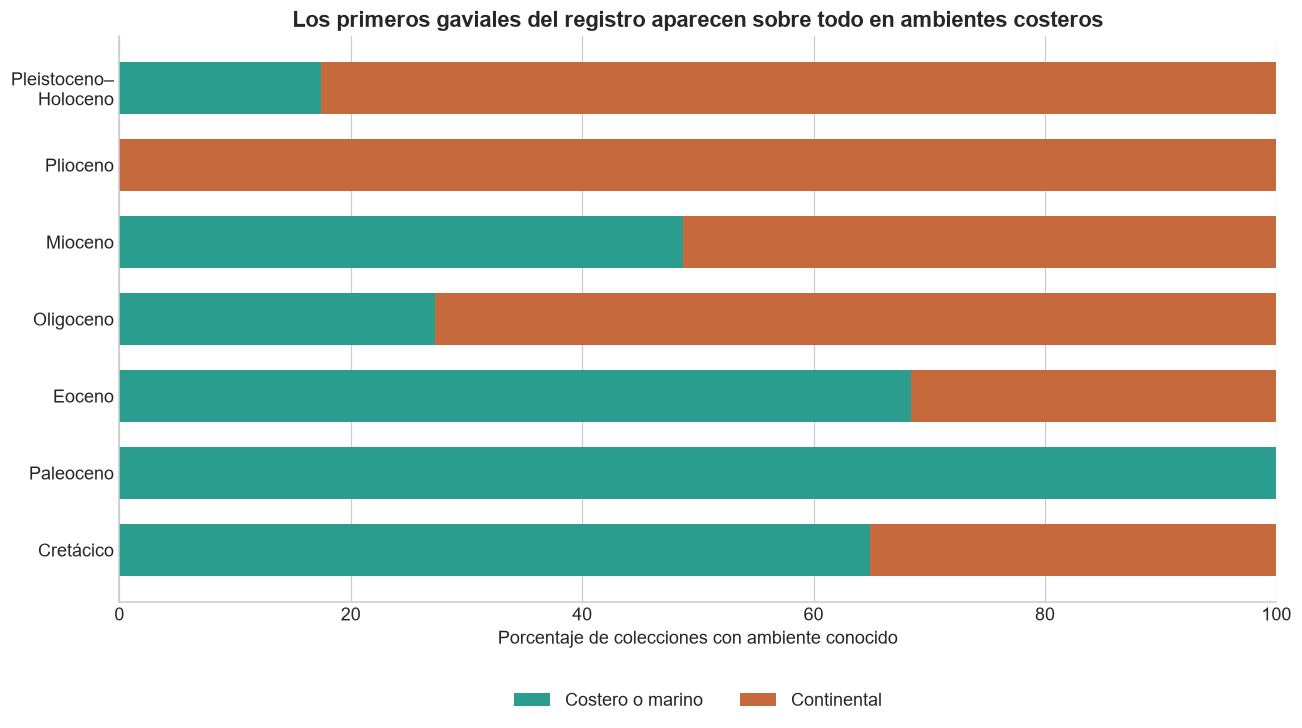

ambiente_agrupado,Continental,Costero o marino
intervalo,,
Cretácico,13,24
Paleoceno,0,12
Eoceno,6,13
Oligoceno,8,3
Mioceno,41,39
Plioceno,13,0
Pleistoceno–\nHoloceno,19,4


In [8]:
# asigno cada colección al intervalo que contiene la edad central del registro
limites = [0, 2.58, 5.333, 23.03, 33.9, 56, 66, 120]
etiquetas = [
    "Pleistoceno–\nHoloceno", "Plioceno", "Mioceno", "Oligoceno",
    "Eoceno", "Paleoceno", "Cretácico"
]

df_colecciones["intervalo"] = pd.cut(
    df_colecciones["edad_central_ma"],
    bins=limites,
    labels=etiquetas,
    right=False,
    include_lowest=True,
)

ambiente_conocido = df_colecciones.loc[
    ~df_colecciones["ambiente_agrupado"].eq("Sin clasificar")
].copy()

resumen_ambiente = (
    ambiente_conocido
    .groupby(["intervalo", "ambiente_agrupado"], observed=True)["collection_no"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(etiquetas[::-1])
)
porcentaje_ambiente = resumen_ambiente.div(resumen_ambiente.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(12, 6.8))
izquierda = np.zeros(len(porcentaje_ambiente))
for categoria, color in [
    ("Costero o marino", color_mar),
    ("Continental", color_tierra),
]:
    valores = porcentaje_ambiente.get(categoria, pd.Series(0, index=porcentaje_ambiente.index))
    ax.barh(
        porcentaje_ambiente.index,
        valores,
        left=izquierda,
        color=color,
        label=categoria,
        height=0.68,
    )
    izquierda += valores.to_numpy()

ax.set_xlim(0, 100)
ax.set_xlabel("Porcentaje de colecciones con ambiente conocido")
ax.set_title("Los primeros gaviales del registro aparecen sobre todo en ambientes costeros")
ax.legend(frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(0.5, -0.22))

fig.tight_layout()
fig.savefig(ruta_imagenes / "03_ambientes_geologicos.png", dpi=180, bbox_inches="tight")
plt.show()

display(resumen_ambiente)

### Tercera pista

En el Cretácico, Paleoceno y Eoceno predominan en la base las colecciones costeras o marinas. A partir del Mioceno, los registros continentales ganan peso. El patrón encaja con una idea clave del estudio: los gaviales antiguos no estaban confinados a ríos; los mares someros podían conectar poblaciones y continentes.

Esto no demuestra por sí solo una ruta migratoria concreta. Los sedimentos marinos pueden fosilizar y exponerse de manera distinta, y el número de colecciones es desigual entre intervalos.

## 6. Un mapa sin mapa: 120 millones de años de paleolatitudes

Las coordenadas actuales no indican dónde estaba realmente un yacimiento cuando vivió el animal. PBDB incluye reconstrucciones paleogeográficas que desplazan los continentes hacia su posición aproximada en el pasado.

Represento la paleolatitud frente al tiempo. La franja sombreada entre 30° sur y 30° norte marca de forma deliberadamente amplia el cinturón tropical y subtropical.

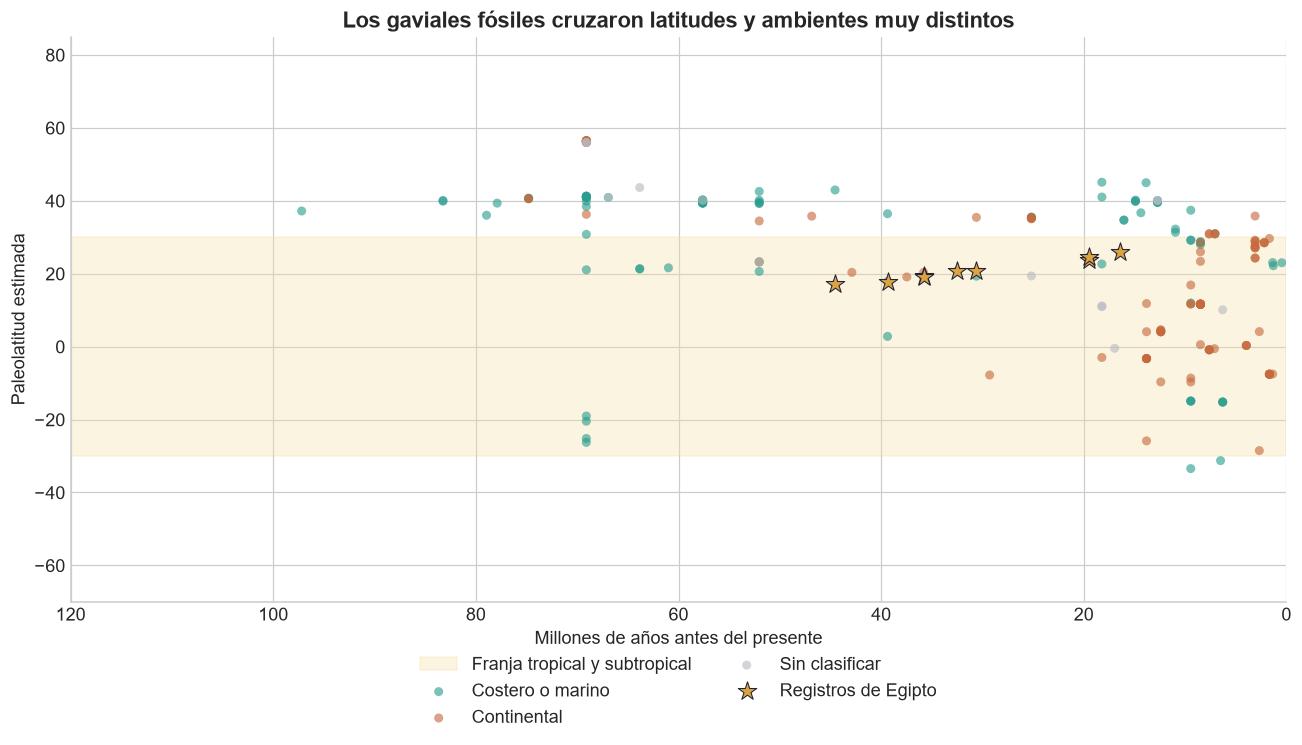

Paleolatitud central de los registros egipcios: 20.8° N


In [9]:
# selecciono registros con paleolatitud disponible
latitudes = df_colecciones.dropna(subset=["paleolat", "edad_central_ma"]).copy()
egipto_lat = latitudes.loc[latitudes["cc"].eq("EG")]

fig, ax = plt.subplots(figsize=(12, 7))
ax.axhspan(-30, 30, color="#F3DFA2", alpha=0.32, label="Franja tropical y subtropical")

for categoria, color in [
    ("Costero o marino", color_mar),
    ("Continental", color_tierra),
    ("Sin clasificar", color_gris),
]:
    parte = latitudes.loc[latitudes["ambiente_agrupado"].eq(categoria)]
    ax.scatter(
        parte["edad_central_ma"],
        parte["paleolat"],
        s=35,
        alpha=0.62,
        color=color,
        edgecolor="none",
        label=categoria,
    )

ax.scatter(
    egipto_lat["edad_central_ma"],
    egipto_lat["paleolat"],
    s=160,
    marker="*",
    color=color_arena,
    edgecolor=color_tinta,
    linewidth=0.7,
    label="Registros de Egipto",
    zorder=4,
)

ax.set_xlim(120, 0)
ax.set_ylim(-70, 85)
ax.set_xlabel("Millones de años antes del presente")
ax.set_ylabel("Paleolatitud estimada")
ax.set_title("Los gaviales fósiles cruzaron latitudes y ambientes muy distintos")
ax.legend(frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(0.5, -0.25))

fig.tight_layout()
fig.savefig(ruta_imagenes / "04_latitud_y_tiempo.png", dpi=180, bbox_inches="tight")
plt.show()

print(
    f"Paleolatitud central de los registros egipcios: "
    f"{egipto_lat['paleolat'].median():.1f}° N"
)

### Cuarta pista

La paleolatitud central de los registros egipcios se sitúa alrededor de **21° norte**, varios grados al sur de la latitud actual de El Cairo. El conjunto global se extiende mucho más allá de Egipto y atraviesa ambos hemisferios.

La gráfica no sigue individuos desplazándose. Superpone fósiles de épocas y linajes distintos para hacer visible la amplitud geográfica de la superfamilia.

## 7. La curva de diversidad también mide cuánto hemos buscado

Divido los últimos 120 millones de años en ventanas de cinco millones. En cada una cuento especies y colecciones únicas usando la edad central.

Si ambas cantidades suben y bajan juntas, una parte de la “diversidad” observada puede deberse a que ciertos intervalos están mejor muestreados. Esto no invalida el registro; define cuánto podemos exigirle.

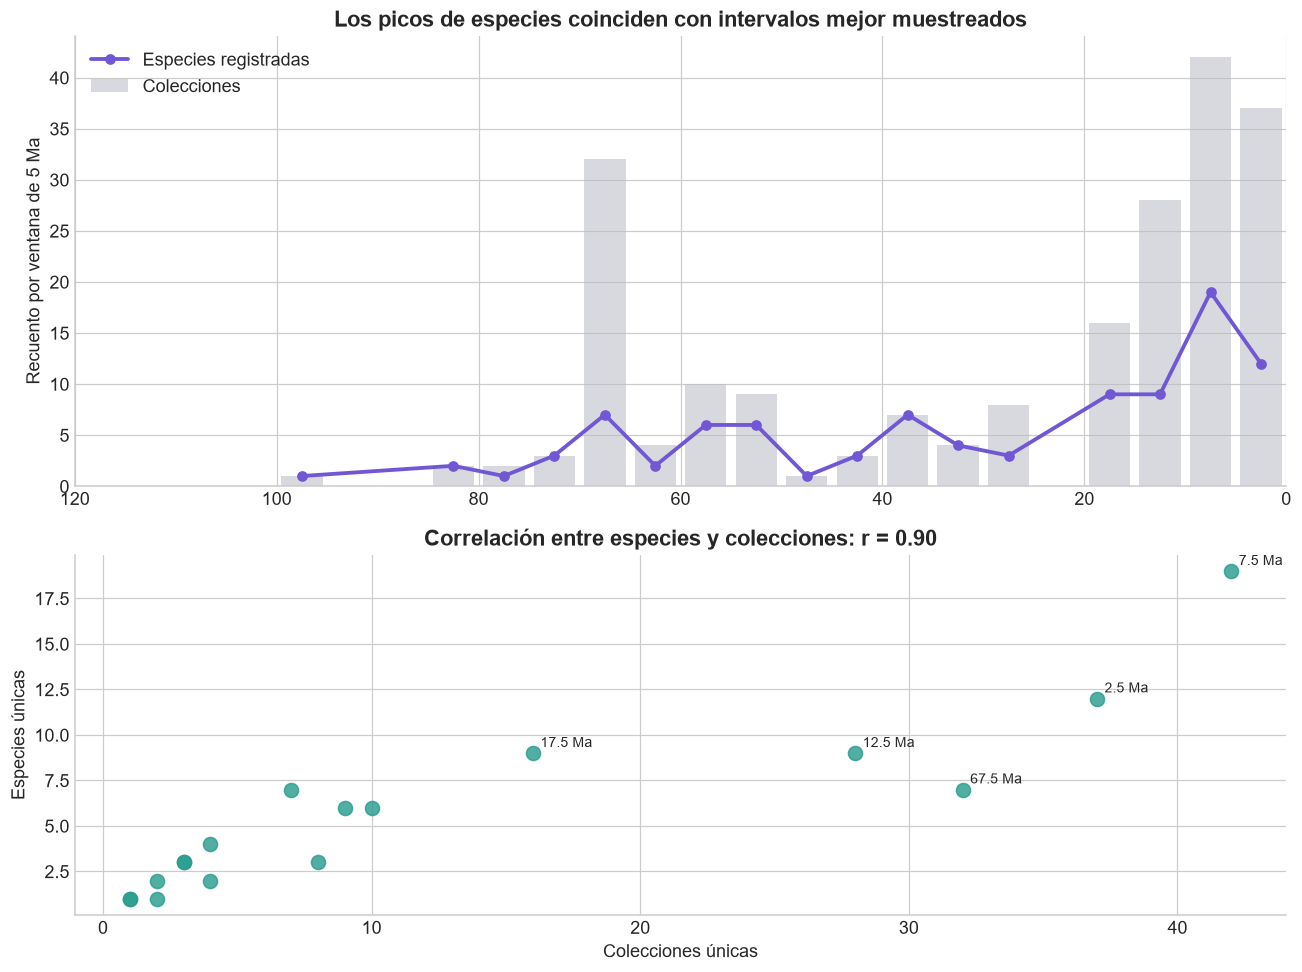

Correlación de Pearson: 0.899


In [10]:
# asigno cada registro a una ventana de cinco millones de años
muestreo = df_colecciones.copy()
muestreo["limite_antiguo_ma"] = (
    np.floor(muestreo["edad_central_ma"] / 5) * 5 + 5
).clip(upper=120)

resumen_muestreo = (
    muestreo.groupby("limite_antiguo_ma", as_index=False)
    .agg(
        especies=("taxon_actualizado", "nunique"),
        colecciones=("collection_no", "nunique"),
        ocurrencias=("occurrence_no", "count"),
    )
    .sort_values("limite_antiguo_ma", ascending=False)
)

correlacion = resumen_muestreo[["especies", "colecciones"]].corr().iloc[0, 1]

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(12, 9), gridspec_kw={"height_ratios": [1.25, 1]}
)

ax1.plot(
    resumen_muestreo["limite_antiguo_ma"] - 2.5,
    resumen_muestreo["especies"],
    color=color_nebula,
    marker="o",
    linewidth=2.5,
    label="Especies registradas",
)
ax1.bar(
    resumen_muestreo["limite_antiguo_ma"] - 2.5,
    resumen_muestreo["colecciones"],
    width=4.1,
    color=color_gris,
    alpha=0.55,
    label="Colecciones",
)
ax1.set_xlim(120, 0)
ax1.set_ylabel("Recuento por ventana de 5 Ma")
ax1.set_title("Los picos de especies coinciden con intervalos mejor muestreados")
ax1.legend(frameon=False)

ax2.scatter(
    resumen_muestreo["colecciones"],
    resumen_muestreo["especies"],
    s=85,
    color=color_mar,
    alpha=0.82,
)
for _, fila in resumen_muestreo.iterrows():
    if fila["especies"] >= 9 or fila["colecciones"] >= 25:
        centro = fila["limite_antiguo_ma"] - 2.5
        ax2.annotate(
            f"{centro:g} Ma",
            (fila["colecciones"], fila["especies"]),
            xytext=(5, 4),
            textcoords="offset points",
            fontsize=9,
        )
ax2.set_xlabel("Colecciones únicas")
ax2.set_ylabel("Especies únicas")
ax2.set_title(f"Correlación entre especies y colecciones: r = {correlacion:.2f}")

fig.tight_layout()
fig.savefig(ruta_imagenes / "05_diversidad_y_muestreo.png", dpi=180, bbox_inches="tight")
plt.show()

resumen_muestreo.to_csv(
    ruta_processed / "resumen_muestreo_5ma.csv",
    index=False,
    encoding="utf-8-sig",
)
print(f"Correlación de Pearson: {correlacion:.3f}")

### Quinta pista

La correlación entre número de especies y número de colecciones es alta. El gran pico del Mioceno tardío coincide con una concentración de yacimientos estudiados. No es correcto leer la curva como un censo directo de la biodiversidad.

El nuevo *Herugavialis* ilustra precisamente por qué el registro cambia: un fósil conocido desde hace un siglo puede alterar el árbol evolutivo cuando se revisa con métodos nuevos. La diversidad paleontológica depende tanto de encontrar como de **volver a mirar**.

## 8. Qué aporta este ángulo a la noticia

El titular habla de una especie nueva y de su vínculo con la Esfinge. Los datos permiten contar una historia más amplia:

1. **La piedra es una cápsula temporal.** El fósil es unas 10.000 veces más antiguo que la Esfinge.
2. **Egipto fue parte de una historia prolongada.** La base registra siete nombres de especie durante más de 30 millones de años.
3. **Los gaviales no siempre fueron animales exclusivamente fluviales.** En las etapas antiguas predominan los registros costeros y marinos.
4. **El Mediterráneo cambió de puerta a barrera.** El estudio propone que el enfriamiento y la bajada del nivel del mar redujeron hábitats, antes de un repunte mioceno y de la desaparición regional asociada a la crisis de salinidad del Mesiniense.
5. **La ciencia también excava museos.** El cambio de nombre llega 99 años después de la descripción original, gracias a nuevas imágenes y comparaciones.

## 9. Límites del análisis

- PBDB es una base viva y desigual: una futura descarga puede contener más registros o una taxonomía actualizada.
- La edad central resume intervalos que en algunos casos abarcan millones de años.
- Las categorías “costero o marino” y “continental” agrupan descripciones sedimentarias heterogéneas.
- El país actual es una etiqueta administrativa; la paleolatitud es una reconstrucción de modelo.
- La correlación entre colecciones y especies demuestra sensibilidad al muestreo, no permite corregir completamente ese sesgo.
- El descenso de diversidad y sus causas climáticas proceden de la hipótesis filogenética del estudio. Esta EDA no prueba causalidad entre temperatura, nivel del mar y extinción.
- Solo se actualiza *Tomistoma cairense* a *Herugavialis cairensis*. Revisar todos los nombres históricos requeriría un trabajo taxonómico independiente.

## 10. Conclusiones

La conexión más interesante entre el gavial y la Esfinge no es la coincidencia de que ambos hayan perdido la punta de la nariz. Es que pertenecen a dos Egiptos casi inconcebiblemente separados: uno humano y desértico; otro tropical, marino y poblado por varios linajes de crocodilianos.

La EDA respalda tres mensajes centrales:

- **el protagonista formaba parte de una diversidad egipcia prolongada**, no de una aparición aislada;
- **los ambientes costeros dominaron gran parte del registro antiguo**, coherente con una expansión favorecida por mares someros;
- **la diversidad observada depende mucho del muestreo**, por lo que los picos deben presentarse con cautela.

El aire fresco de la noticia está ahí: la Gran Esfinge no solo mira hacia la historia de Egipto. Su propia roca mira decenas de millones de años más atrás, hacia un océano desaparecido.

## Fuentes

- Burke, P. M. J. et al. (2026). *Cranial anatomy of the Middle Eocene Egyptian crocodylian Herugavialis cairensis provides new insights into gavialoid diversity in the Mediterranean region*. **Royal Society Open Science**, 13, 261173. https://doi.org/10.1098/rsos.261173
- Paleobiology Database. Ocurrencias de Gavialoidea, consulta reproducible descargada el 14 de octubre de 2026. https://paleobiodb.org/
- Buehler, J. (2026). *An extinct crocodilian was found among rocks that built the Great Sphinx*. Science News. https://www.sciencenews.org/article/extinct-crocodilian-rocks-great-sphinx
- Smithsonian Magazine (2026). *A Century Ago, an Extinct Crocodilian's Skull Was Found in the Rocks That Built the Sphinx*. https://www.smithsonianmag.com/smart-news/a-century-ago-an-extinct-crocidilians-skull-was-found-in-the-rocks-that-built-the-sphinx-turns-out-it-belonged-to-a-new-species-180989641/

**Reproducibilidad:** el archivo original de PBDB se conserva en `data/raw`; los datos derivados se escriben en `data/processed`; todas las figuras se guardan en `img`.